# Disciplina: Deep Learning
## Lab 06 - Métricas de Performance e Avaliação do Aprendizado

**Orientações para o Aluno:**
- Este laboratório tem como objetivo a aplicação prática de métricas de avaliação para modelos de Redes Neurais.
- Utilize as bibliotecas `scikit-learn`, `matplotlib` e `numpy` para as análises.
- Leia atentamente os enunciados e execute o código do gabarito para entender o fluxo de avaliação de um modelo.

### 🔹 Questão 1: Classificação Binária e Métricas de Erro
**Enunciado:** Em problemas de classificação binária, a acurácia nem sempre é a melhor métrica (especialmente em datasets desbalanceados). Crie um cenário de predição e calcule a Acurácia, Precisão, Recall e F1-Score.

**Requisitos:**
- Criar vetores de rótulos reais e preditos.
- Utilizar o `classification_report` do sklearn.

**Dica:** Pense em um sistema de detecção de fraude onde o erro de falso negativo é mais crítico.

In [10]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 1. Carregando dataset real (0: maligno, 1: benigno)
data = load_breast_cancer()
X, y = data.data, data.target

# 2. Dividindo e treinando um modelo simples
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

# 3. Gerando predições
y_pred = model.predict(X_test)

# 4. Calculando métricas
print(f'Acurácia: {accuracy_score(y_test, y_pred):.2f}')
print(f'Precisão: {precision_score(y_test, y_pred):.2f}')
print(f'Recall: {recall_score(y_test, y_pred):.2f}')
print(f'F1-Score: {f1_score(y_test, y_pred):.2f}')

print('\nRelatório de Classificação:\n', classification_report(y_test, y_pred, target_names=data.target_names))

Acurácia: 0.98
Precisão: 0.98
Recall: 0.98
F1-Score: 0.98

Relatório de Classificação:
               precision    recall  f1-score   support

   malignant       0.97      0.97      0.97        63
      benign       0.98      0.98      0.98       108

    accuracy                           0.98       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171



### 🔹 Questão 2: Matriz de Confusão para Visualização de Erros
**Enunciado:** A Matriz de Confusão permite visualizar onde o modelo está confundindo as classes. Gere uma matriz para um problema de 3 classes (Cachorro, Gato, Pássaro) e a visualize graficamente.

**Requisitos:**
- Gerar matriz de confusão.
- Utilizar `ConfusionMatrixDisplay` para plotagem.

**Dica:** Verifique quais classes possuem maior intersecção de erro.

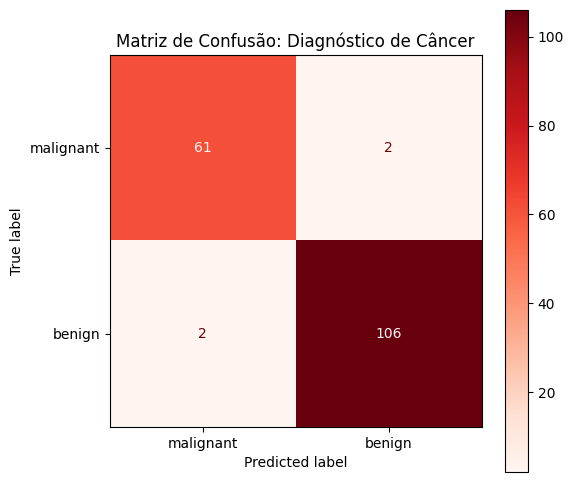

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Utilizando os dados do dataset de câncer de mama carregados anteriormente
cm = confusion_matrix(y_test, y_pred)

# 2. Plotagem da Matriz
fig, ax = plt.subplots(figsize=(6,6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap='Reds', ax=ax)
plt.title('Matriz de Confusão: Diagnóstico de Câncer')
plt.show()

### 🔹 Questão 3: Curva ROC e AUC
**Enunciado:** A métrica AUC-ROC avalia a performance do modelo em diferentes limiares de decisão. Plote a curva ROC para um classificador probabilístico.

**Requisitos:**
- Utilizar probabilidades (`y_score`) em vez de rótulos binários.
- Calcular a área sob a curva (AUC).

**Dica:** A curva mostra o tradeoff entre Taxa de Falso Positivo e Verdadeiro Positivo.

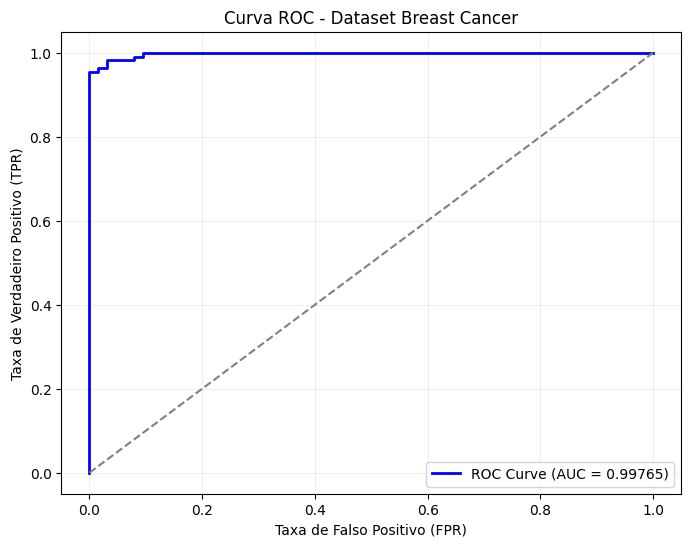

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Obtendo as probabilidades da classe positiva
y_probs = model.predict_proba(X_test)[:, 1]

# 2. Calculando curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc = roc_auc_score(y_test, y_probs)

# 3. Plotagem
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {auc:.5f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('Taxa de Falso Positivo (FPR)')
plt.ylabel('Taxa de Verdadeiro Positivo (TPR)')
plt.title('Curva ROC - Dataset Breast Cancer')
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()

### 🔹 Questão 4: Curvas de Aprendizado e Overfitting
**Enunciado:** Analise o comportamento do erro durante o treinamento. Embora tenhamos usado uma Regressão Logística, em Redes Neurais monitoramos as curvas de Loss para evitar o overfitting.

**Requisitos:**
- Visualizar a evolução do erro (Loss) simulando um treinamento iterativo ou utilizando o histórico de um modelo MLP.
- Identificar a convergência do modelo.

**Dica:** Utilize um `MLPClassifier` para extrair a curva de perda real (`loss_curve_`).

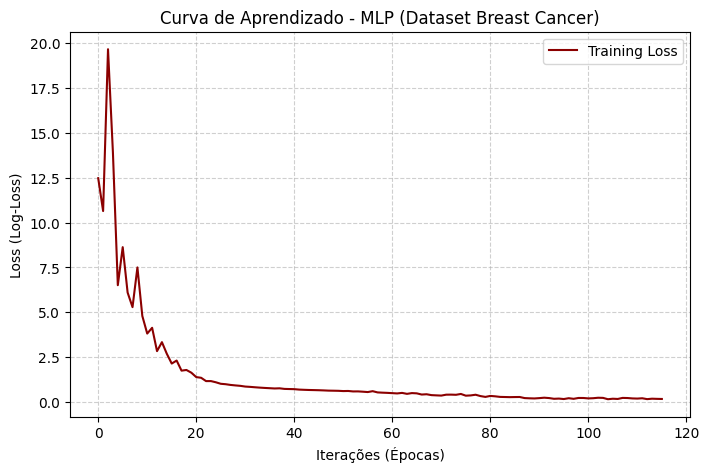

In [13]:
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt

# 1. Treinando um Perceptron Multicamadas (Rede Neural) para obter a curva de perda real
mlp = MLPClassifier(hidden_layer_sizes=(10,), max_iter=300, random_state=42, learning_rate_init=0.01)
mlp.fit(X_train, y_train)

# 2. Plotagem da Curva de Perda (Loss Curve)
plt.figure(figsize=(8, 5))
plt.plot(mlp.loss_curve_, color='darkred', label='Training Loss')
plt.title('Curva de Aprendizado - MLP (Dataset Breast Cancer)')
plt.xlabel('Iterações (Épocas)')
plt.ylabel('Loss (Log-Loss)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show() # O gráfico mostra a rede neural convergindo para um erro mínimo